## Clone BasicSR repo

In [1]:
!rm -rf BasicSR
!git clone https://github.com/xinntao/BasicSR.git
%cd BasicSR

Cloning into 'BasicSR'...
remote: Enumerating objects: 5924, done.
remote: Total 5924 (delta 0), reused 0 (delta 0), pack-reused 5924 (from 1)
Receiving objects: 100% (5924/5924), 4.14 MiB | 9.52 MiB/s, done.
Resolving deltas: 100% (3757/3757), done.
/content/BasicSR


## Set up the enviroment


In [2]:
# Install pytorch
!pip install torch torchvision

# Check torch and cuda versions
import torch
print('Torch Version: ', torch.__version__)
print('CUDA Version: ', torch.version.cuda)
print('CUDNN Version: ', torch.backends.cudnn.version())
print('CUDA Available:', torch.cuda.is_available())

Torch Version:  2.5.1+cu121
CUDA Version:  12.1
CUDNN Version:  90100
CUDA Available: True


In [3]:
# Install requirements
!pip install -r requirements.txt
# Install BasicSR without cuda extentions
!python setup.py develop

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 11.0 MB/s eta 0:00:00
/usr/local/lib/python3.10/dist-packages/setuptools/__init__.py:94: _DeprecatedInstaller: setuptools.installer and fetch_build_eggs are deprecated.
!!

        ********************************************************************************
        Requirements should be satisfied by a PEP 517 installer.
        If you are using pip, you can try `pip install --use-pep517`.
        ********************************************************************************

!!
  dist.fetch_build_eggs(dist.setup_requires)
running develop
/usr/local/lib/python3.10/dist-packages/setuptools/command/develop.py:41: EasyInstallDeprecationWarning: easy_install command is deprecated.
!!

       

## Download pretrained models

In [4]:
!python scripts/download_pretrained_models.py ESRGAN

Download 63.8 MB / 63.8 MB: 100% 2043/2043 [00:05<00:00, 369.26chunk/s]
Download 63.8 MB / 63.8 MB: 100% 2043/2043 [00:04<00:00, 429.81chunk/s]


## Download datasets

In [5]:
import os
import requests
from zipfile import ZipFile
from PIL import Image

def download_and_extract(url, extract_to):
    filename = url.split("/")[-1]
    filepath = os.path.join(extract_to, filename)

    if not os.path.exists(extract_to):
        os.makedirs(extract_to)

    # Download the dataset‍
    print(f"Downloading {filename}...")
    with requests.get(url, stream=True) as response:
        response.raise_for_status()
        with open(filepath, "wb") as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
    print(f"Downloaded {filename}.")

    # Extract the dataset‍
    print(f"Extracting {filename}...")
    with ZipFile(filepath, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"Extracted {filename}.")
    os.remove(filepath)
    print(f"Removed {filename}.")


# Main Code‍
urban100_url = "https://github.com/jbhuang0604/SelfExSR/archive/refs/heads/master.zip"
base_dir = "datasets/Urban100"
download_and_extract(urban100_url, base_dir)

Downloaded master.zip.
Extracting master.zip...
Extracted master.zip.
Removed master.zip.


## Split the dataset into low-resolution and high-resolution folders

In [6]:
def split_lr_hr(imgs_dir, hr_dir, lr_dir):
    os.makedirs(hr_dir, exist_ok=True)
    os.makedirs(lr_dir, exist_ok=True)

    for img_name in os.listdir(imgs_dir):
        img_path = os.path.join(imgs_dir, img_name)
        if img_name[-6: -4] == "HR":
            Image.open(img_path).save(os.path.join(hr_dir, img_name))
        else:
            Image.open(img_path).save(os.path.join(lr_dir, img_name))

imgs_dir = "datasets/Urban100/SelfExSR-master/data/Urban100/image_SRF_2"
if imgs_dir:
    print(f"All images in: {imgs_dir}")
    lr_dir = os.path.join(base_dir, "LR")
    hr_dir = os.path.join(base_dir, "HR")
    split_lr_hr(imgs_dir, hr_dir, lr_dir)
else:
    print("All images directory not found. Please check the extracted files.")

All images in: datasets/Urban100/SelfExSR-master/data/Urban100/image_SRF_2


## Apply the model

In [7]:
import cv2
import glob
import numpy as np
import os
import torch

from basicsr.archs.rrdbnet_arch import RRDBNet

# configuration
model_path = 'experiments/pretrained_models/ESRGAN/ESRGAN_SRx4_DF2KOST_official-ff704c30.pth'
folder = 'datasets/Urban100/LR'
device = 'cuda'

device = torch.device(device)

# set up model
model = RRDBNet(
    num_in_ch=3, num_out_ch=3, num_feat=64, num_block=23, num_grow_ch=32)
model.load_state_dict(torch.load(model_path)['params'], strict=True)
model.eval()
model = model.to(device)

os.makedirs("datasets/Urban100/Result", exist_ok=True)

for idx, path in enumerate(sorted(glob.glob(os.path.join(folder, '*')))):
    imgname = os.path.splitext(os.path.basename(path))[0]
    print(idx, imgname)
    # read image
    img = cv2.imread(path, cv2.IMREAD_COLOR).astype(np.float32) / 255.
    img = torch.from_numpy(np.transpose(img[:, :, [2, 1, 0]],
                                        (2, 0, 1))).float()
    img = img.unsqueeze(0).to(device)
    # inference
    with torch.no_grad():
        output = model(img)
    # save image
    output = output.data.squeeze().float().cpu().clamp_(0, 1).numpy()
    output = np.transpose(output[[2, 1, 0], :, :], (1, 2, 0))
    output = (output * 255.0).round().astype(np.uint8)
    cv2.imwrite(f'datasets/Urban100/Result/{imgname[:-3]}_ESRGAN.png', output)

<ipython-input-7-3452d6ab7761>:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path)['params'], strict=True)


0 img_001_SRF_2_LR
1 img_002_SRF_2_LR
2 img_003_SRF_2_LR
3 img_004_SRF_2_LR
4 img_005_SRF_2_LR
5 img_006_SRF_2_LR
6 img_007_SRF_2_LR
7 img_008_SRF_2_LR
8 img_009_SRF_2_LR
9 img_010_SRF_2_LR
10 img_011_SRF_2_LR
11 img_012_SRF_2_LR
12 img_013_SRF_2_LR
13 img_014_SRF_2_LR
14 img_015_SRF_2_LR
15 img_016_SRF_2_LR
16 img_017_SRF_2_LR
17 img_018_SRF_2_LR
18 img_019_SRF_2_LR
19 img_020_SRF_2_LR
20 img_021_SRF_2_LR
21 img_022_SRF_2_LR
22 img_023_SRF_2_LR
23 img_024_SRF_2_LR
24 img_025_SRF_2_LR
25 img_026_SRF_2_LR
26 img_027_SRF_2_LR
27 img_028_SRF_2_LR
28 img_029_SRF_2_LR
29 img_030_SRF_2_LR
30 img_031_SRF_2_LR
31 img_032_SRF_2_LR
32 img_033_SRF_2_LR
33 img_034_SRF_2_LR
34 img_035_SRF_2_LR
35 img_036_SRF_2_LR
36 img_037_SRF_2_LR
37 img_038_SRF_2_LR
38 img_039_SRF_2_LR
39 img_040_SRF_2_LR
40 img_041_SRF_2_LR
41 img_042_SRF_2_LR
42 img_043_SRF_2_LR
43 img_044_SRF_2_LR
44 img_045_SRF_2_LR
45 img_046_SRF_2_LR
46 img_047_SRF_2_LR
47 img_048_SRF_2_LR
48 img_049_SRF_2_LR
49 img_050_SRF_2_LR
50 img_051

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Show results

We show and compare the input image, ESRGAN results and the Ground-truth (GT) image for the first 3 instances.

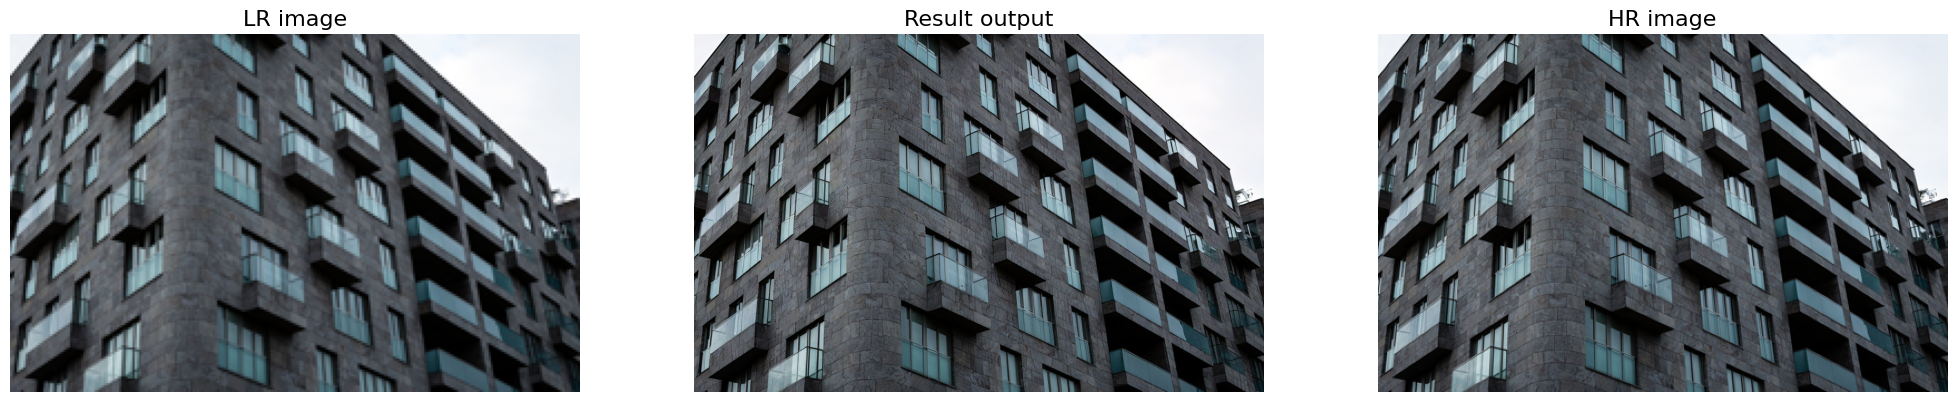

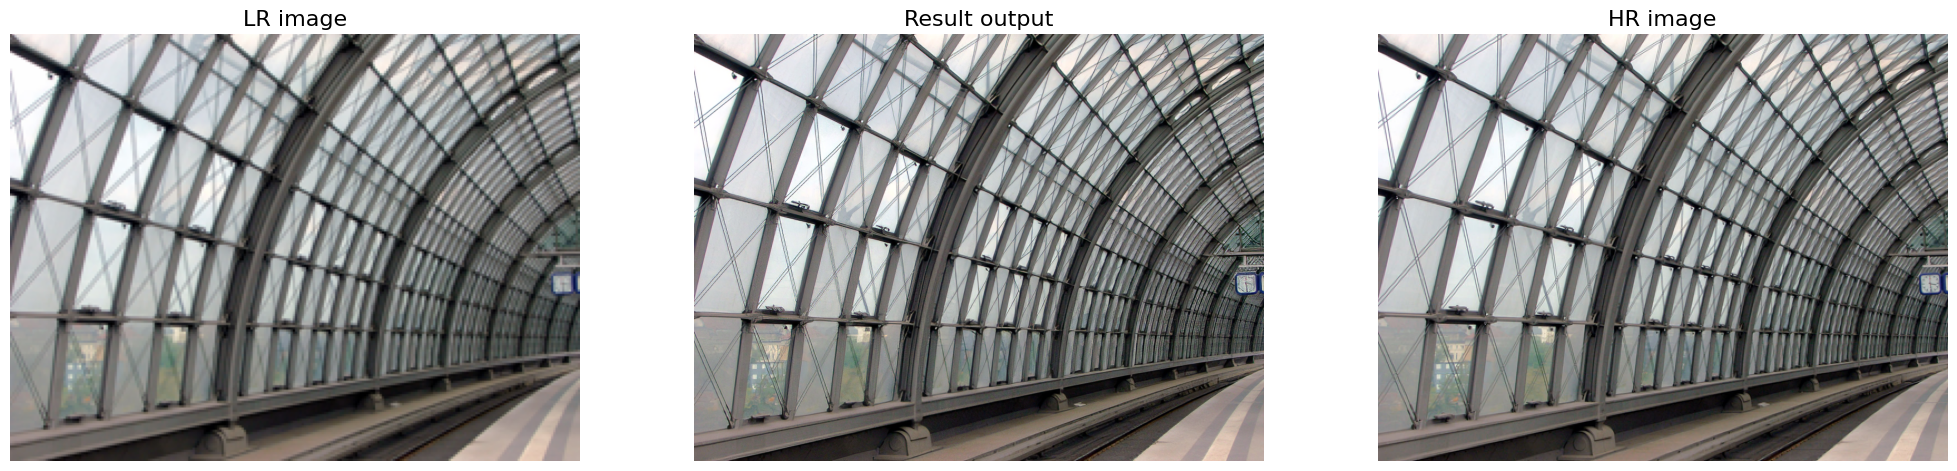

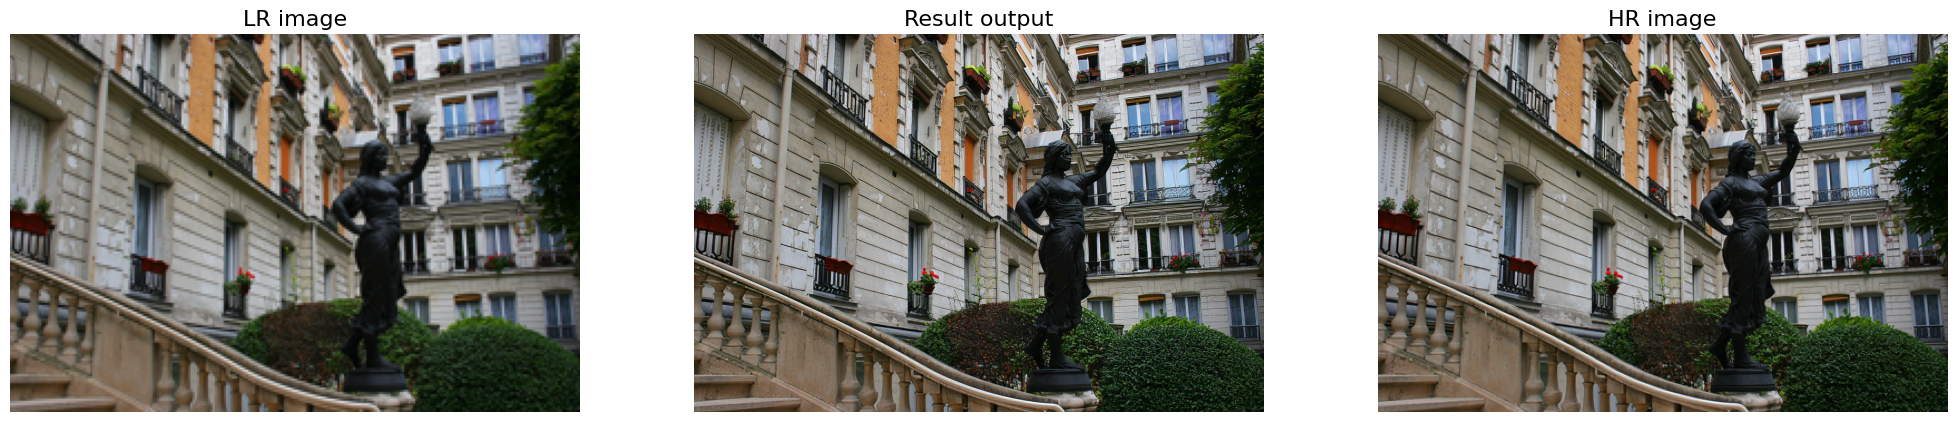

In [9]:
import cv2
import matplotlib.pyplot as plt

def imread(img_path):
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  return img

for i in range(1, 4):
# read images
    img_input = imread(f'datasets/Urban100/LR/img_{i:0>3}_SRF_2_LR.png')
    img_esrgan = imread(f'datasets/Urban100/Result/img_{i:0>3}_SRF_2_ESRGAN.png')
    img_gt = imread(f'datasets/Urban100/HR/img_{i:0>3}_SRF_2_HR.png')

    # show and compare the results
    fig = plt.figure(figsize=(25, 10))
    ax1 = fig.add_subplot(1, 3, 1)
    plt.title('LR image', fontsize=16)
    ax1.axis('off')
    ax2 = fig.add_subplot(1, 3, 2)
    plt.title('Result output', fontsize=16)
    ax2.axis('off')
    ax3 = fig.add_subplot(1, 3, 3)
    plt.title('HR image', fontsize=16)
    ax3.axis('off')
    ax1.imshow(img_input)
    ax2.imshow(img_esrgan)
    ax3.imshow(img_gt)

# Try it on uploaded images

## 1. Upload images from local machine

In [28]:
import os
from google.colab import files
import shutil

upload_folder = 'datasets/Upload'
result_folder = 'datasets/Result'

if os.path.isdir(upload_folder):
    shutil.rmtree(upload_folder)
if os.path.isdir(result_folder):
    shutil.rmtree(result_folder)
os.mkdir(upload_folder)
os.mkdir(result_folder)

# upload images
uploaded = files.upload()
for filename in uploaded.keys():
  dst_path = os.path.join(upload_folder, filename)
  print(f'move {filename} to {dst_path}')
  shutil.move(filename, dst_path)

Saving 1.png to 1.png
move 1.png to datasets/Upload/1.png


## 2. Use model

In [29]:
folder = "datasets/Upload"

for idx, path in enumerate(sorted(glob.glob(os.path.join(folder, '*')))):
    imgname = os.path.splitext(os.path.basename(path))[0]
    print(idx, imgname)
    # read image
    img = cv2.imread(path, cv2.IMREAD_COLOR).astype(np.float32) / 255.
    img = torch.from_numpy(np.transpose(img[:, :, [2, 1, 0]],
                                        (2, 0, 1))).float()
    img = img.unsqueeze(0).to(device)
    # inference
    with torch.no_grad():
        output = model(img)
    # save image
    output = output.data.squeeze().float().cpu().clamp_(0, 1).numpy()
    output = np.transpose(output[[2, 1, 0], :, :], (1, 2, 0))
    output = (output * 255.0).round().astype(np.uint8)
    cv2.imwrite(f'datasets/Result/{imgname}_ESRGAN.png', output)

0 1


## 3. Show the results

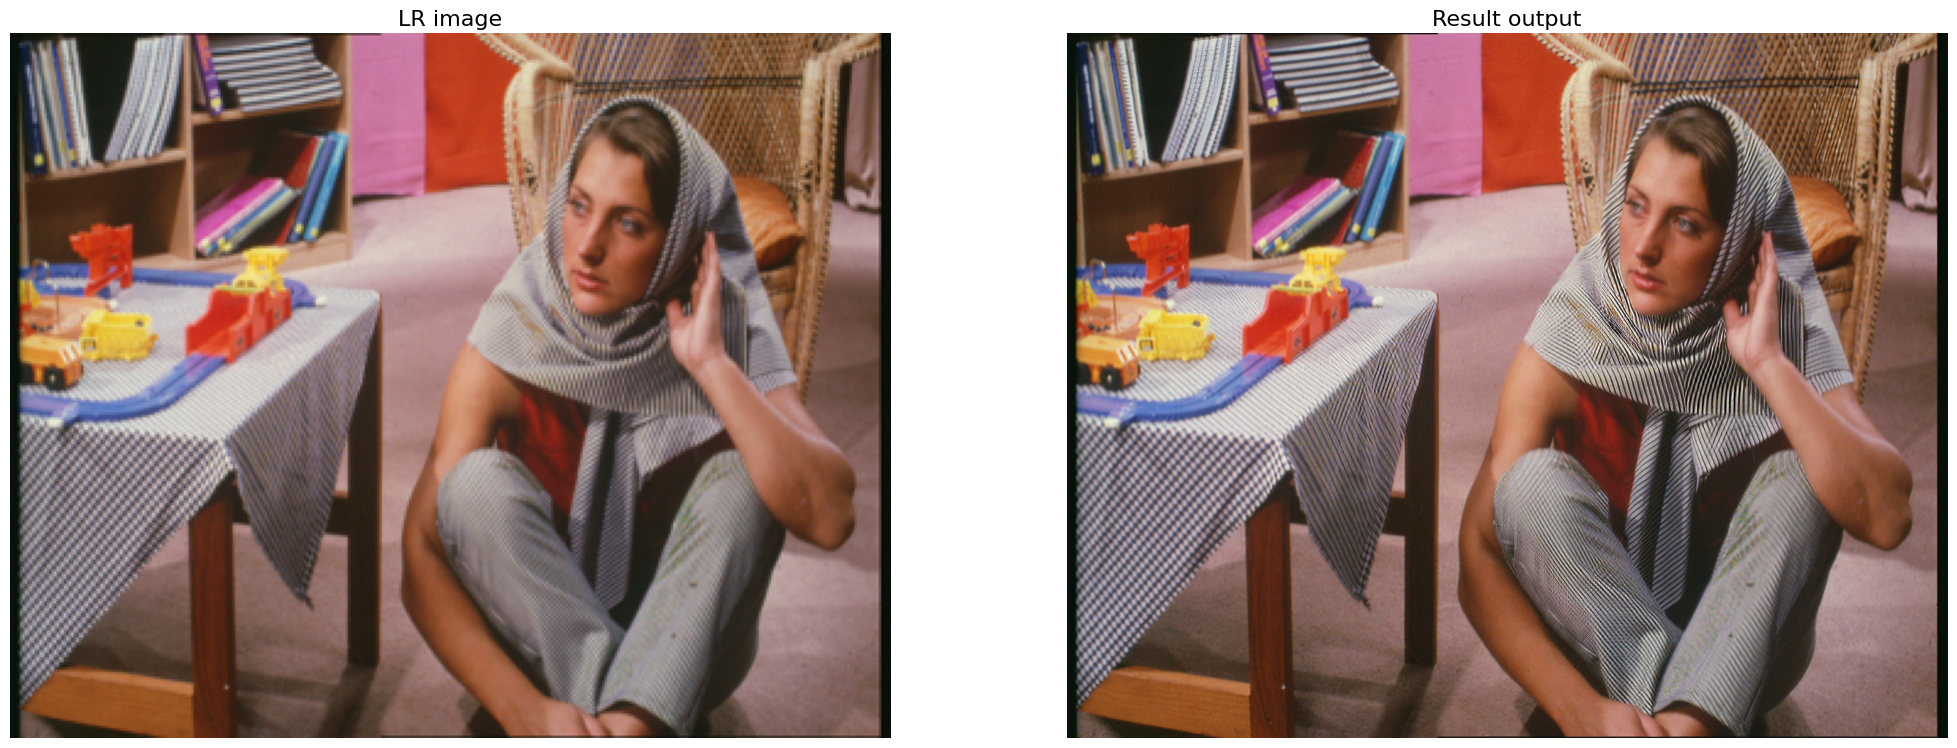

In [30]:
import cv2
import matplotlib.pyplot as plt

def imread(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

upload = "datasets/Upload"
result = "datasets/Result"

for path1, path2 in zip(sorted(glob.glob(os.path.join(upload, '*'))), sorted(glob.glob(os.path.join(result, '*')))):
    imgname1 = os.path.splitext(os.path.basename(path1))[0]
    imgname2 = os.path.splitext(os.path.basename(path2))[0]
    img_input = imread(f"datasets/Upload/{imgname1}.png")
    img_esrgan = imread(f"datasets/Result/{imgname2}.png")

    # show and compare the results
    fig = plt.figure(figsize=(25, 10))
    ax1 = fig.add_subplot(1, 2, 1)
    plt.title('LR image', fontsize=16)
    ax1.axis('off')
    ax2 = fig.add_subplot(1, 2, 2)
    plt.title('Result output', fontsize=16)
    ax2.axis('off')
    ax1.imshow(img_input)
    ax2.imshow(img_esrgan)

## 4. Download the result

In [31]:
from google.colab import files

# download the result
result_folder = "datasets/Result"
print(f'Download {result_folder}')
os.system(f'zip -r -j download.zip {result_folder}/*')
files.download("download.zip")

Download datasets/Result


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Limitations
ESRGAN is mainly developped for research purpose and there are several limitations for practical usage.
1. Scale. It now only supports for X4 upsampling.
2. Kernel mismatch. The provided ESRGAN model is trained with MATLAB bicubic downsampling kernel (you can treat it as a blur type). If the blur type of the real image is different from the bicubic downsampling kernel, which is the usual case, the results are not satisfactory. You may need to fine-tune the pretrained ESRGAN model to improve the output quality.
3. Other degradations like JPEG compressions and noise. The pretrained ESRGAN model is for super-resolution, and does not take the JPEG compressions and noise into considerations. So it cannot handle these degradations. You may first remove theses degradations or fine-tune it to give this model such ability.
